# Práctica 4 · Ensambles sobre clasificadores ajustados
##Introducción a la Ciencia de Datos
###María Guadalupe Villanueva Utrilla

¿Cuánto mejoran bagging, boosting, votación y stacking a los cinco clasificadores de la Práctica 3? ¿Se comporta igual la familia ganadora en Bank Marketing?


## 1. Configuración y versiones

Se fija la semilla, se registran versiones y se declara el presupuesto de las búsquedas. Los cinco modelos originales de la Práctica 3 no se vuelven a optimizar. Las cuatro búsquedas obligatorias de ensambles en deserción evalúan 50 configuraciones cada una. Para el banco se hace una evaluación anidada, que exige más tiempo pero evita seleccionar hiperparámetros usando el pliegue de prueba.


In [88]:
import sys
import subprocess
import importlib.metadata as paquetes
from importlib.util import find_spec

instalar = []
for nombre, requisito in [
    ("lightgbm", "lightgbm>=4.3,<5"),
    ("catboost", "catboost>=1.2.10,<2"),
    ("scikit-learn", "scikit-learn>=1.6,<1.10"),]:
    try:
        from packaging.requirements import Requirement
        if paquetes.version(nombre) not in Requirement(requisito).specifier:
            instalar.append(requisito)
    except paquetes.PackageNotFoundError:
        instalar.append(requisito)

if instalar:
    print("instalando librerías necesarias:", instalar)
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *instalar])

import sys
import time
import json
import warnings
import zipfile
from pathlib import Path
from urllib.request import urlretrieve

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy
import sklearn
import joblib
import lightgbm
import catboost

from IPython.display import display, Markdown
from scipy.stats import randint, loguniform
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, MinMaxScaler
from sklearn.impute import SimpleImputer
from sklearn.model_selection import StratifiedKFold, RandomizedSearchCV, cross_validate, cross_val_predict, TunedThresholdClassifierCV
from sklearn.metrics import f1_score, recall_score, confusion_matrix, ConfusionMatrixDisplay, make_scorer
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB, MultinomialNB, BernoulliNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import BaggingClassifier, AdaBoostClassifier, VotingClassifier, StackingClassifier, RandomForestClassifier, ExtraTreesClassifier
from sklearn.calibration import CalibratedClassifierCV
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

semilla = 42
cv_desercion = StratifiedKFold(n_splits=5, shuffle=True, random_state=semilla)
cv_banco = StratifiedKFold(n_splits=5, shuffle=True, random_state=2026)
semilla_busqueda = 42
n_busquedas_ensamble = 50  #mínimo obligatorio por modelo optimizado de la parte 1
n_busquedas_banco_lgbm = 24  #búsqueda interna por pliegue externo
n_busquedas_banco_cat = 16  #catboost suele necesitar más tiempo
n_trabajos = 2  #evita saturar la memoria o crear muchos procesos
rondas = [1, 5, 10, 20, 50, 100, 200, 300, 400]

warnings.filterwarnings("ignore", category=FutureWarning)
print("python:", sys.version.split()[0])
print("scikit-learn:", sklearn.__version__, "pandas:", pd.__version__)
print("numpy:", np.__version__, "scipy:", scipy.__version__)
print("lightgbm:", lightgbm.__version__, "catboost:", catboost.__version__)
print("joblib:", joblib.__version__)

python: 3.13.18
scikit-learn: 1.6.1 pandas: 2.2.3
numpy: 2.4.6 scipy: 1.16.3
lightgbm: 4.6.0 catboost: 1.2.10
joblib: 1.6.0


## 2. Checkpoints, ejecución y copia opcional a Drive

Cada búsqueda y evaluación se guarda después de terminar. Si Colab se desconecta, se vuelven a cargar las etapas terminadas y no se pierden sus resultados. No se guardan ajustes incompletos dentro de una búsqueda RandomizedSearchCV.

In [89]:
usar_drive = False  #cambiar a true en colab para conservar checkpoints entre sesiones
carpeta_resultados = Path("resultados_p4")
carpeta_resultados.mkdir(exist_ok=True)
carpeta_drive = None

if usar_drive:
    try:
        from google.colab import drive
        drive.mount("/content/drive")
        carpeta_drive = Path("/content/drive/MyDrive/practica4_ensambles")
        carpeta_drive.mkdir(parents=True, exist_ok=True)
    except ImportError:
        print("no en colab: solo se usan rutas relativas")


def guardar_resultado(nombre, objeto):
    ruta = carpeta_resultados / f"{nombre}.joblib"
    temporal = carpeta_resultados / f"{nombre}.tmp"
    joblib.dump(objeto, temporal, compress=3)  #escribe primero un archivo temporal
    temporal.replace(ruta)
    if carpeta_drive is not None:
        import shutil
        shutil.copy2(ruta, carpeta_drive / ruta.name)
    print("guardado:", ruta)


def recuperar_resultado(nombre):
    local = carpeta_resultados / f"{nombre}.joblib"
    remoto = carpeta_drive / f"{nombre}.joblib" if carpeta_drive is not None else None
    ruta = local if local.exists() else remoto
    if ruta is None or not ruta.exists():
        return None
    try:
        return joblib.load(ruta)  #cargar solo checkpoints propios
    except Exception as error:
        print(f"checkpoint incompatible ({nombre}): {error}")
        return None


print("resultados:", carpeta_resultados.resolve())
print("checkpoints disponibles:", len(list(carpeta_resultados.glob("*.joblib"))))

resultados: /content/resultados_p4
checkpoints disponibles: 16


In [90]:
# recuperar los checkpoints incluidos en resultados_p4.zip
# coloca el zip en la misma carpeta de trabajo antes de ejecutar todo
from pathlib import Path
import zipfile
import shutil

zip_resultados = Path("resultados_p4.zip")
carpeta_resultados = Path("resultados_p4")
carpeta_resultados.mkdir(exist_ok=True)

if zip_resultados.is_file():
    nuevos = 0
    existentes = 0
    with zipfile.ZipFile(zip_resultados) as paquete:
        archivos = [info for info in paquete.infolist() if not info.is_dir()]
        for info in archivos:
            nombre_zip = Path(info.filename.replace("\\", "/"))
            # admite ZIP con carpeta resultados_p4/ o archivos .joblib en su raíz
            if nombre_zip.parts and nombre_zip.parts[0] == "resultados_p4":
                partes = nombre_zip.parts[1:]
            else:
                partes = nombre_zip.parts
            if len(partes) != 1 or not partes[0].endswith(".joblib"):
                continue
            destino = carpeta_resultados / partes[0]
            if destino.exists():
                existentes += 1
                continue  # no reemplazar un checkpoint local ya generado
            with paquete.open(info) as entrada, destino.open("wb") as salida:
                shutil.copyfileobj(entrada, salida)
            nuevos += 1
    print(f"checkpoints recuperados del zip: {nuevos} nuevos; {existentes} ya existentes")
else:
    print("no se encontró resultados_p4.zip: los experimentos faltantes se ejecutarán normalmente")

print("checkpoints locales disponibles:", len(list(carpeta_resultados.glob("*.joblib"))))

checkpoints recuperados del zip: 0 nuevos; 16 ya existentes
checkpoints locales disponibles: 16


# Parte 1 · Deserción estudiantil
## 3. Descargar entrenamiento y seleccionar los atributos del primer semestre

Se trabaja con el CSV de entrenamiento de la Práctica 3. La información del segundo semestre se excluye porque no estaba disponible cuando debía hacerse la predicción. Para comparar de manera justa los cinco modelos y sus ensambles se respetan las columnas de entrada y las transformaciones de esa práctica.

In [91]:
carpeta_datos = Path("datos")
carpeta_datos.mkdir(exist_ok=True)
base_curso = "https://raw.githubusercontent.com/husseinlopez/icd2026/main/datos/"

for nombre in ["desercion-entrenamiento.csv", "desercion-prueba.csv"]:
    archivo = carpeta_datos / nombre
    if not archivo.exists():
        urlretrieve(base_curso + nombre, archivo)  #descarga solo si falta el csv

entrenamiento = pd.read_csv(carpeta_datos / "desercion-entrenamiento.csv")
prueba = pd.read_csv(carpeta_datos / "desercion-prueba.csv")
entrenamiento["Target"] = entrenamiento["Target"].str.strip().str.lower()

columnas = [c for c in prueba.columns if c in entrenamiento.columns and c != "id"]
x_desercion = entrenamiento[columnas].copy()
y_desercion = entrenamiento["Target"].copy()
clases_desercion = ["dropout", "enrolled", "graduate"]

assert len(x_desercion) == 3539 and len(prueba) == 885
assert set(y_desercion.unique()) == set(clases_desercion)
assert not any("2nd sem" in c for c in x_desercion.columns)

print("datos de deserción:", x_desercion.shape)
print("segundo semestre excluido:", [c for c in entrenamiento.columns if "2nd sem" in c])
display(y_desercion.value_counts().rename("estudiantes").to_frame())

datos de deserción: (3539, 30)
segundo semestre excluido: ['Curricular units 2nd sem (credited)', 'Curricular units 2nd sem (enrolled)', 'Curricular units 2nd sem (evaluations)', 'Curricular units 2nd sem (approved)', 'Curricular units 2nd sem (grade)', 'Curricular units 2nd sem (without evaluations)']


,estudiantes
Target,
graduate,1767
dropout,1137
enrolled,635


###Revisión
 Cada registro representa un estudiante de licenciatura. Las tres clases no tienen la misma frecuencia, por lo que se emplea F1 macro en vez de basarse únicamente en exactitud. No se usa información posterior al primer semestre

## 4. Cinco variables académicas adicionales y preprocesamiento

En la Práctica 3 se observó que cinco tasas relacionadas con el rendimiento del primer semestre mejoraron el SVM de 0.6812 a 0.6853 y la regresión logística de 0.6805 a 0.6870. Son operaciones por fila, sin calcular estadísticas globales, de modo que es seguro construirlas antes de crear los pliegues. Los tres clasificadores restantes se alimentarán con sus columnas originales; SVM y regresión logística utilizan las columnas ampliadas si se recuperan sus configuraciones mejoradas.

Se mantiene el procesamiento de las variables categóricas mediante OneHotEncoder. Para árboles no se escala, para SVM, kNN y regresión logística se usa estandarización, para Naive Bayes se usa Min-Max porque se compararon variantes que requieren valores no negativos.

In [92]:
def agregar_caracteristicas(datos):
    datos = datos.copy()
    inscritas = datos["Curricular units 1st sem (enrolled)"]
    aprobadas = datos["Curricular units 1st sem (approved)"]
    evaluadas = datos["Curricular units 1st sem (evaluations)"]
    sin_evaluacion = datos["Curricular units 1st sem (without evaluations)"]
    nota = datos["Curricular units 1st sem (grade)"]
    datos["tasa_aprobacion"] = aprobadas / inscritas.replace(0, np.nan)
    datos["tasa_exito"] = aprobadas / evaluadas.replace(0, np.nan)
    datos["tasa_evaluacion"] = evaluadas / inscritas.replace(0, np.nan)
    datos["tasa_sin_evaluacion"] = sin_evaluacion / inscritas.replace(0, np.nan)
    datos["rendimiento_ponderado"] = nota * datos["tasa_aprobacion"]
    nuevas = ["tasa_aprobacion", "tasa_exito", "tasa_evaluacion", "tasa_sin_evaluacion", "rendimiento_ponderado"]
    datos[nuevas] = datos[nuevas].fillna(0)
    return datos

x_desercion = agregar_caracteristicas(x_desercion)

nominales_uci = {
    "Marital status", "Application mode", "Course", "Daytime/evening attendance",
    "Previous qualification", "Nacionality", "Nationality", "Mother's qualification",
    "Father's qualification", "Mother's occupation", "Father's occupation", "Displaced",
    "Educational special needs", "Debtor", "Tuition fees up to date", "Gender",
    "Scholarship holder", "International"}


def preprocesamiento_desercion(datos, modo="arbol", incluir_mejora=True):
    columnas_usadas = datos.columns if incluir_mejora else [c for c in datos.columns if c not in {
        "tasa_aprobacion", "tasa_exito", "tasa_evaluacion", "tasa_sin_evaluacion", "rendimiento_ponderado"}]
    categoricas = [c for c in columnas_usadas if c in nominales_uci]
    numericas = [c for c in columnas_usadas if c not in nominales_uci]
    cat = Pipeline([
        ("relleno", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),])
    pasos_num = [("relleno", SimpleImputer(strategy="median"))]
    if modo == "escalado":
        pasos_num.append(("escala", StandardScaler()))
    if modo == "bayes":
        pasos_num.append(("escala", MinMaxScaler()))
    return ColumnTransformer([
        ("categorias", cat, categoricas),
        ("numericas", Pipeline(pasos_num), numericas)], remainder="drop")

print("atributos originales:", len(columnas), "con indicadores:", x_desercion.shape[1])

atributos originales: 30 con indicadores: 35


**Interpretación.** Se conservan las decisiones de preprocesamiento de la Práctica 3. Las tasas permiten comparar proporciones aunque los estudiantes tengan distintas cargas académicas. En cada evaluación, la imputación, codificación y escala se vuelven a ajustar dentro del pliegue de entrenamiento mediante el pipeline.

## 5. Recuperar los cinco clasificadores base **sin volver a optimizarlos**

Si está disponible el archivo busquedas.joblib de la Práctica 3, se recuperan de él los hiperparámetros originales del árbol, Naive Bayes y kNN. Para SVM y regresión logística se utilizan las versiones mejoradas (svm_mejorado.joblib, logistica_mejorada.joblib) cuando existen; en caso contrario se recuperan los parámetros ya anotados en nuestro análisis anterior.

In [93]:
carpeta_p3 = Path("datos_modelos_p3")  #guardar aquí busquedas.joblib o los parámetros originales exportados
carpeta_p3.mkdir(exist_ok=True)


def cargar_p3(nombre):
    rutas = [carpeta_p3 / nombre, Path("resultados_p3") / nombre]
    #permite usar un drive previamente montado, sin obligar al profesor a montarlo
    rutas.append(Path("/content/drive/MyDrive/practica_desercion") / nombre)
    for ruta in rutas:
        if ruta.exists():
            try:
                print("checkpoint de práctica 3:", ruta)
                return joblib.load(ruta)  #solo cargar archivos propios de la práctica 3
            except Exception as error:
                print("no se pudo cargar:", ruta, error)
    return None


busquedas_p3 = cargar_p3("busquedas.joblib")
svm_p3 = cargar_p3("svm_mejorado.joblib")
logistica_p3 = cargar_p3("logistica_mejorada.joblib")
ruta_parametros_p3 = carpeta_p3 / "parametros_originales_p3.json"

#estas son las dos configuraciones que NO debemos reemplazar por valores de respaldo
nombres_obligatorios_p3 = ["árbol de decisión", "naive bayes"]
clases_nb = {"GaussianNB": GaussianNB, "MultinomialNB": MultinomialNB, "BernoulliNB": BernoulliNB}


def convertir_parametro(valor):
    if isinstance(valor, np.generic):
        return valor.item()
    if isinstance(valor, (str, int, float, bool)) or valor is None:
        return valor
    raise TypeError(f"parámetro no exportable: {type(valor).__name__}")


if busquedas_p3 is not None:
    #el checkpoint original tiene prioridad sobre cualquier json anterior
    parametros_originales_p3 = {}
    for nombre in nombres_obligatorios_p3:
        if nombre not in busquedas_p3 or not hasattr(busquedas_p3[nombre], "best_params_"):
            raise ValueError(f"el checkpoint de práctica 3 no contiene la búsqueda optimizada de {nombre}")
        params = dict(busquedas_p3[nombre].best_params_)
        if nombre == "naive bayes":
            variante = params.pop("modelo", None)
            if variante is None or type(variante).__name__ not in clases_nb:
                raise ValueError("no se puede recuperar la variante ganadora de naive bayes")
            params["modelo"] = type(variante).__name__
        parametros_originales_p3[nombre] = {
            clave: convertir_parametro(valor) for clave, valor in params.items()
        }
    ruta_parametros_p3.write_text(
        json.dumps({"origen": "busquedas.joblib / práctica 3",
                    "parametros": parametros_originales_p3},
                   ensure_ascii=False, indent=2, sort_keys=True),
        encoding="utf-8")
    print("parámetros originales exportados:", ruta_parametros_p3)
elif ruta_parametros_p3.exists():
    contenido_p3 = json.loads(ruta_parametros_p3.read_text(encoding="utf-8"))
    if contenido_p3.get("origen") != "busquedas.joblib / práctica 3":
        raise ValueError("el archivo json no indica que proviene del checkpoint original de práctica 3")
    parametros_originales_p3 = contenido_p3["parametros"]
    print("parámetros originales recuperados:", ruta_parametros_p3)
else:
    raise FileNotFoundError(
        "Falta el checkpoint original de la Práctica 3. Copia busquedas.joblib desde "
        "Mi unidad/practica_desercion a datos_modelos_p3/ y ejecuta esta celda. "
        "Se creará parametros_originales_p3.json, que debes agregar al repositorio "
        "para que el profesor ejecute Restart & Run All sin Google Drive. "
        "No se usarán parámetros inventados ni configuraciones de respaldo."
    )

#validar que ambos contienen los parámetros de la búsqueda original
parametros_arbol = parametros_originales_p3.get("árbol de decisión", {})
parametros_nb = parametros_originales_p3.get("naive bayes", {})
if not {"modelo__criterion", "modelo__max_depth", "modelo__min_samples_leaf",
        "modelo__ccp_alpha", "modelo__class_weight"}.issubset(parametros_arbol):
    raise ValueError("faltan hiperparámetros originales del árbol de decisión")
if parametros_nb.get("modelo") not in clases_nb:
    raise ValueError("falta la variante original de naive bayes")
if "modelo__var_smoothing" not in parametros_nb and "modelo__alpha" not in parametros_nb:
    raise ValueError("faltan los hiperparámetros originales de naive bayes")

parametros_respaldo = {
    "knn": {"modelo__n_neighbors": 5, "modelo__weights": "uniform", "modelo__p": 1, "modelo__leaf_size": 58},
    "svm": {"modelo__C": 14.851035064938554, "modelo__gamma": 0.004515157628843042,
            "modelo__kernel": "rbf", "modelo__degree": 3, "modelo__class_weight": "balanced"},
    "regresión logística": {"modelo__C": 0.13820379228637, "modelo__penalty": "elasticnet",
                             "modelo__l1_ratio": 0.25, "modelo__class_weight": "balanced"}}


def mejor_configuracion(nombre):
    if nombre in nombres_obligatorios_p3:
        params = dict(parametros_originales_p3[nombre])
        if nombre == "naive bayes":
            params["modelo"] = clases_nb[params["modelo"]]()  #recuperar la variante ganadora
        return params
    if nombre == "svm" and svm_p3 is not None:
        return dict(svm_p3.best_params_)
    if nombre == "regresión logística" and logistica_p3 is not None:
        return dict(logistica_p3.best_params_)
    if busquedas_p3 is not None and nombre in busquedas_p3:
        return dict(busquedas_p3[nombre].best_params_)
    return dict(parametros_respaldo[nombre])


def crear_base(nombre):
    modo = "arbol" if nombre == "árbol de decisión" else "bayes" if nombre == "naive bayes" else "escalado"
    mejora = nombre in ["svm", "regresión logística"]
    pre = preprocesamiento_desercion(x_desercion, modo, incluir_mejora=mejora)
    if nombre == "árbol de decisión":
        estimador = DecisionTreeClassifier(random_state=semilla)
    elif nombre == "naive bayes":
        estimador = GaussianNB()
    elif nombre == "knn":
        estimador = KNeighborsClassifier(algorithm="kd_tree")  #evita el error de etiquetas de la práctica 3
    elif nombre == "svm":
        estimador = SVC()
    else:
        estimador = LogisticRegression(solver="saga", max_iter=1000, tol=1e-3, random_state=semilla)
    modelo = Pipeline([("preprocesamiento", pre), ("modelo", estimador)])
    params = mejor_configuracion(nombre)
    if nombre == "naive bayes" and "modelo" in params:
        params = dict(params)
        modelo.set_params(modelo=clone(params.pop("modelo")))  #conserva la variante ganadora
    modelo.set_params(**params)
    return modelo


nombres_base = ["árbol de decisión", "naive bayes", "knn", "svm", "regresión logística"]
modelos_base = {nombre: crear_base(nombre) for nombre in nombres_base}
for nombre in nombres_base:
    print(nombre, '->', modelos_base[nombre].named_steps['modelo'].__class__.__name__)

#si había resultados hechos con parámetros de respaldo, no reutilizarlos como si fueran originales
import hashlib
firma_actual_p3 = hashlib.sha256(
    json.dumps(parametros_originales_p3, sort_keys=True, ensure_ascii=False).encode("utf-8")
).hexdigest()
firma_anterior_p3 = recuperar_resultado("firma_modelos_p3")
if firma_anterior_p3 != firma_actual_p3:
    tabla_anterior = recuperar_resultado("tabla_desercion")
    if isinstance(tabla_anterior, dict):
        dependientes_p3 = ["árbol de decisión", "naive bayes", "votación dura",
                          "votación suave", "stacking logístico"]
        obsoletos = [nombre for nombre in dependientes_p3 if nombre in tabla_anterior]
        if obsoletos:
            for nombre in obsoletos:
                tabla_anterior.pop(nombre)
            guardar_resultado("tabla_desercion", tabla_anterior)
            print("evaluaciones que se recalcularán con parámetros originales:", obsoletos)
    #las correlaciones de error también dependen de los clasificadores originales
    for carpeta_cache in [carpeta_resultados, carpeta_drive]:
        if carpeta_cache is None:
            continue
        ruta_oof = carpeta_cache / "predicciones_oof_base.joblib"
        if ruta_oof.exists():
            destino_oof = carpeta_cache / "predicciones_oof_base_anteriores.joblib"
            ruta_oof.replace(destino_oof)  #se preserva una copia de los resultados previos
    guardar_resultado("firma_modelos_p3", firma_actual_p3)


checkpoint de práctica 3: /content/drive/MyDrive/practica_desercion/busquedas.joblib
checkpoint de práctica 3: /content/drive/MyDrive/practica_desercion/svm_mejorado.joblib
checkpoint de práctica 3: /content/drive/MyDrive/practica_desercion/logistica_mejorada.joblib
parámetros originales exportados: datos_modelos_p3/parametros_originales_p3.json
árbol de decisión -> DecisionTreeClassifier
naive bayes -> BernoulliNB
knn -> KNeighborsClassifier
svm -> SVC
regresión logística -> LogisticRegression


###Revisión
En esta ejecución los cinco modelos base quedaron definidos sin volver a buscar hiperparámetros. Al evaluarlos con los cinco pliegues se obtuvo un F1 macro de 0.6281 para el árbol, 0.2242 para Naive Bayes, 0.5769 para kNN, 0.6853 para SVM y 0.6870 para regresión logística. La logística fue la mejor de las cinco, aunque su diferencia frente al SVM fue pequeña (0.0017).

Aquí hay una limitación importante, avisó que no encontró los checkpoints originales del árbol ni de Naive Bayes, así que utilizó configuraciones de respaldo. Esto ayuda a explicar por qué Naive Bayes quedó tan bajo, especialmente si se compara con el 0.5890 de la búsqueda anterior. De hecho, tuvo una sensibilidad de 0.9244 para enrolled, pero un F1 macro de apenas 0.2242; reconocer muchos casos de una clase no significa clasificar bien las tres. Por lo tanto, estos dos resultados no deben presentarse como una reproducción exacta de los modelos optimizados de la Práctica 3.

## 6. Funciones de evaluación y tabla acumulada

Esta función llama a cross_validate con los mismos cinco pliegues, obtiene F1 macro, sensibilidad de enrolled, desviación y tiempo. Guarda los resultados al terminar, así una desconexión no obliga a repetir todo. La desviación se calcula entre los cinco pliegues.

In [95]:
resultados_desercion = recuperar_resultado("tabla_desercion")
if resultados_desercion is None:
    resultados_desercion = {}
modelos_desercion = dict(modelos_base)


def sensibilidad_clase(clase):
    return make_scorer(recall_score, labels=[clase], average="macro", zero_division=0)


def evaluar_desercion(nombre, modelo, descripcion="", tiempo_busqueda=0.0):
    modelos_desercion[nombre] = modelo
    if nombre in resultados_desercion:
        print("recuperado:", nombre)
        return resultados_desercion[nombre]
    print("evaluando:", nombre, flush=True)
    inicio = time.perf_counter()
    resultado = cross_validate(
        modelo, x_desercion, y_desercion, cv=cv_desercion,
        scoring={"f1": "f1_macro", "sens": sensibilidad_clase("enrolled")},
        n_jobs=n_trabajos, error_score="raise")
    fila = {
        "modelo": nombre, "familia": descripcion,
        "f1_media": float(resultado["test_f1"].mean()),
        "f1_std": float(resultado["test_f1"].std(ddof=1)),
        "sens_enrolled": float(resultado["test_sens"].mean()),
        "tiempo_cv_s": float(np.sum(resultado["fit_time"])),
        "tiempo_busqueda_s": float(tiempo_busqueda),
        "tiempo_pared_s": float(time.perf_counter() - inicio)}
    resultados_desercion[nombre] = fila
    guardar_resultado("tabla_desercion", resultados_desercion)
    return fila


for nombre, modelo in modelos_base.items():
    evaluar_desercion(nombre, modelo, "base fijo de práctica 3")

display(pd.DataFrame(resultados_desercion.values()).sort_values("f1_media", ascending=False).round(4))

recuperado: árbol de decisión
recuperado: naive bayes
recuperado: knn
recuperado: svm
recuperado: regresión logística


,modelo,familia,f1_media,f1_std,sens_enrolled,tiempo_cv_s,tiempo_busqueda_s,tiempo_pared_s
6,catboost,boosting optimizado,0.6975,0.0092,0.6110,10.6295,440.2275,6.2266
5,lightgbm,boosting optimizado,0.6960,0.0152,0.6016,6.2940,178.1494,3.9722
15,stacking logístico,votación / stacking,0.6901,0.0061,0.6205,148.1619,0.0000,92.9557
2,regresión logística,base fijo de práctica 3,0.6870,0.0110,0.5890,30.3664,0.0000,16.2282
4,extra trees,bagging optimizado,0.6869,0.0157,0.5764,24.4426,512.6632,14.0247
3,random forest,bagging optimizado,0.6861,0.0132,0.5512,9.9422,647.4579,5.7378
1,svm,base fijo de práctica 3,0.6853,0.0062,0.6173,17.0622,0.0000,13.5474
13,votación dura,votación / stacking,0.6790,0.0055,0.6268,28.7307,0.0000,20.9414
14,votación suave,votación / stacking,0.6779,0.0081,0.6646,48.3847,0.0000,35.7313
8,bagging 400,varianza,0.6620,0.0227,0.3307,91.7099,0.0000,NaN


###Revisión
Esta primera tabla constituye la referencia que deberán superar los ensambles. La comparación válida es entre las medias de la nueva validación cruzada, no entre las puntuaciones máximas obtenidas durante las búsquedas de la Práctica 3. tiempo_cv_s suma los tiempos de ajuste de los cinco pliegues.

## 7. Experimento de varianza: árbol completo frente a bagging (1 a 400 árboles)

Se entrena un árbol sin límite de profundidad y un conjunto de árboles completos sobre distintas muestras bootstrap. warm_start=True permite aumentar la cantidad de árboles sin entrenar todo el conjunto desde cero dentro de cada pliegue externo. El preprocesamiento se ajusta exclusivamente con entrenamiento.

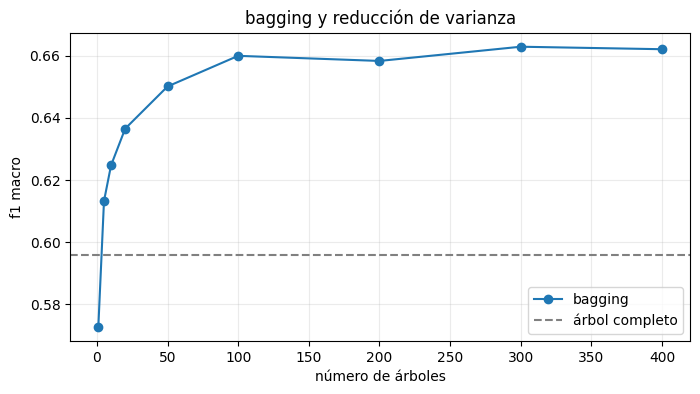

árbol completo: 0.5957
bagging con 400: 0.662


In [96]:
curva_bagging = recuperar_resultado("curva_bagging")
if curva_bagging is None:
    print("calculando curva de bagging...", flush=True)
    puntos = recuperar_resultado("parcial_curva_bagging") or []
    completos = {int(fila["pliegue"]) for fila in puntos if fila["n"] == 400}
    for numero, (it, iv) in enumerate(cv_desercion.split(x_desercion, y_desercion), 1):
        if numero in completos:
            continue
        inicio_pliegue = time.perf_counter()
        pre = clone(preprocesamiento_desercion(x_desercion, "arbol", incluir_mejora=False))
        xtr = pre.fit_transform(x_desercion.iloc[it]); xva = pre.transform(x_desercion.iloc[iv])
        ytr = y_desercion.iloc[it]; yva = y_desercion.iloc[iv]
        arbol = DecisionTreeClassifier(max_depth=None, random_state=semilla)
        arbol.fit(xtr, ytr)
        pred_arbol = arbol.predict(xva)
        puntos.append({"pliegue": numero, "n": 0,
                       "f1": f1_score(yva, pred_arbol, average="macro"),
                       "sens": recall_score(yva, pred_arbol, labels=["enrolled"], average="macro", zero_division=0),
                       "tiempo_s": time.perf_counter() - inicio_pliegue})
        bagging = BaggingClassifier(estimator=DecisionTreeClassifier(max_depth=None),
                                    n_estimators=1, warm_start=True, bootstrap=True,
                                    n_jobs=n_trabajos, random_state=semilla)
        for n in rondas:
            bagging.set_params(n_estimators=n)
            bagging.fit(xtr, ytr)
            pred_bag = bagging.predict(xva)
            puntos.append({"pliegue": numero, "n": n,
                           "f1": f1_score(yva, pred_bag, average="macro"),
                           "sens": recall_score(yva, pred_bag, labels=["enrolled"], average="macro", zero_division=0),
                           "tiempo_s": time.perf_counter() - inicio_pliegue})
        guardar_resultado("parcial_curva_bagging", puntos)
        print("pliegue de bagging terminado:", numero, "/5", flush=True)
    curva_bagging = pd.DataFrame(puntos)
    guardar_resultado("curva_bagging", curva_bagging)

resumen_bagging = curva_bagging.groupby("n")["f1"].agg(["mean", "std"])
fig, ax = plt.subplots(figsize=(8, 4))
resumen_bagging.loc[resumen_bagging.index > 0, "mean"].plot(ax=ax, marker="o", label="bagging")
ax.axhline(resumen_bagging.loc[0, "mean"], color="gray", linestyle="--", label="árbol completo")
ax.set(xlabel="número de árboles", ylabel="f1 macro", title="bagging y reducción de varianza")
ax.grid(alpha=0.25); ax.legend(); display(fig); plt.close(fig)
print("árbol completo:", round(resumen_bagging.loc[0, "mean"], 4))
print("bagging con 400:", round(resumen_bagging.loc[400, "mean"], 4))

###Revisión
El árbol sin límite de profundidad obtuvo un F1 macro de 0.5957, mientras que bagging con 400 árboles llegó a 0.6620. La mejora fue de 0.0663 puntos, es decir aproximadamente 6.63 puntos porcentuales de F1 macro. La curva crece rápido al principio: cerca de 100 árboles ya se encuentra alrededor de 0.66, y después las mejoras son pequeñas. Entre 300 y 400 prácticamente se mantiene el mismo resultado.

Esto es consistente con la idea de que bagging reduce la varianza. Un árbol profundo puede cambiar mucho al modificar los estudiantes usados para entrenarlo; al combinar muchos árboles entrenados con muestras distintas, esas variaciones individuales tienen menos efecto en la predicción final. Aun así, el resultado de bagging no supera a la regresión logística base (0.6870), así que reducir la varianza no implica ganar automáticamente frente a todos los clasificadores.

## 8. Experimento de sesgo: tocón frente a AdaBoost (1 a 400 rondas)

El tocón usa profundidad uno y solo puede hacer una partición. AdaBoost combina muchos tocones entrenados secuencialmente para corregir errores anteriores. Se entrena una sola vez hasta 400 rondas y se utiliza `staged_predict()` para extraer el F1 de cada etapa sin repetir 400 entrenamientos.

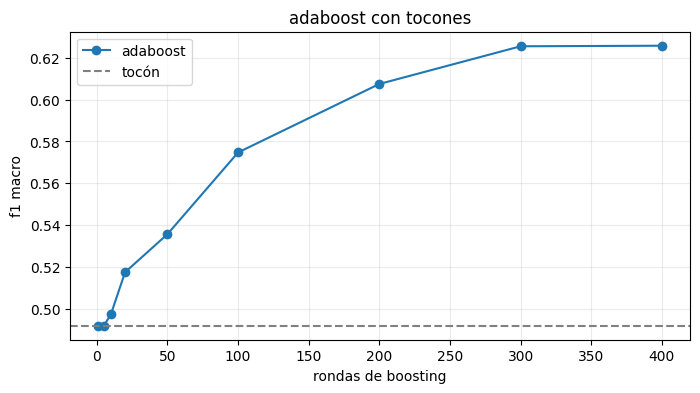

tocón: 0.492
adaboost con 400: 0.6257


In [97]:
curva_boosting = recuperar_resultado("curva_adaboost")
if curva_boosting is None:
    print("calculando curva de adaboost...", flush=True)
    puntos = recuperar_resultado("parcial_curva_adaboost") or []
    completos = {int(fila["pliegue"]) for fila in puntos if fila["n"] == 400}
    for numero, (it, iv) in enumerate(cv_desercion.split(x_desercion, y_desercion), 1):
        if numero in completos:
            continue
        inicio_pliegue = time.perf_counter()
        pre = clone(preprocesamiento_desercion(x_desercion, "arbol", incluir_mejora=False))
        xtr = pre.fit_transform(x_desercion.iloc[it]); xva = pre.transform(x_desercion.iloc[iv])
        ytr = y_desercion.iloc[it]; yva = y_desercion.iloc[iv]
        tocon = DecisionTreeClassifier(max_depth=1, random_state=semilla)
        tocon.fit(xtr, ytr)
        pred_tocon = tocon.predict(xva)
        puntos.append({"pliegue": numero, "n": 0,
                       "f1": f1_score(yva, pred_tocon, average="macro"),
                       "sens": recall_score(yva, pred_tocon, labels=["enrolled"], average="macro", zero_division=0),
                       "tiempo_s": time.perf_counter() - inicio_pliegue})
        ada = AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=1, random_state=semilla),
                                  n_estimators=400, learning_rate=0.5, random_state=semilla)
        ada.fit(xtr, ytr)
        etapa = {}
        for i, pred in enumerate(ada.staged_predict(xva), 1):
            if i in rondas:
                etapa[i] = (f1_score(yva, pred, average="macro"),
                            recall_score(yva, pred, labels=["enrolled"], average="macro", zero_division=0))
        for n in rondas:
            # si adaboost se detiene pronto, la última etapa disponible se conserva
            valor = etapa[n] if n in etapa else etapa[max(i for i in etapa if i <= n)]
            puntos.append({"pliegue": numero, "n": n, "f1": valor[0], "sens": valor[1],
                           "tiempo_s": time.perf_counter() - inicio_pliegue})
        guardar_resultado("parcial_curva_adaboost", puntos)
        print("pliegue de adaboost terminado:", numero, "/5", flush=True)
    curva_boosting = pd.DataFrame(puntos)
    guardar_resultado("curva_adaboost", curva_boosting)

resumen_boosting = curva_boosting.groupby("n")["f1"].agg(["mean", "std"])
fig, ax = plt.subplots(figsize=(8, 4))
resumen_boosting.loc[resumen_boosting.index > 0, "mean"].plot(ax=ax, marker="o", label="adaboost")
ax.axhline(resumen_boosting.loc[0, "mean"], color="gray", linestyle="--", label="tocón")
ax.set(xlabel="rondas de boosting", ylabel="f1 macro", title="adaboost con tocones")
ax.grid(alpha=0.25); ax.legend(); display(fig); plt.close(fig)
print("tocón:", round(resumen_boosting.loc[0, "mean"], 4))
print("adaboost con 400:", round(resumen_boosting.loc[400, "mean"], 4))

###Revisión
El tocón que solo puede hacer una partición, obtuvo un F1 macro de 0.4920. Al combinar tocones con AdaBoost, el resultado subió hasta 0.6257 después de 400 rondas: una mejora de 0.1337 puntos. En la gráfica el crecimiento es gradual, especialmente hasta unas 300 rondas; de 300 a 400 casi no se observa cambio.

En este caso boosting ayuda principalmente a reducir el sesgo de una regla demasiado simple. Cada ronda añade otro tocón y da mayor importancia a ejemplos que la combinación anterior no resolvió bien, de modo que el conjunto puede representar decisiones más complejas. Sin embargo, su sensibilidad para enrolled fue de solo 0.2173 al final, y su F1 todavía quedó por debajo del bagging de 400 árboles (0.6620). Por eso aunque AdaBoost mejora mucho al tocón, no es de los mejores modelos para este problema.

## 9. Votación dura, votación suave y stacking

Se combinan los cinco clasificadores base sin modificar sus hiperparámetros. En votación dura se utiliza la clase elegida por mayoría; en suave se promedian probabilidades. Como SVM no produce probabilidades calibradas por defecto, se incluye CalibratedClassifierCV dentro del estimador SVM, con tres pliegues internos. Esto no deja utilizar el pliegue externo de validación para calibrar. En stacking, el metamodelo es regresión logística y sus características proceden de predicciones fuera de pliegue de los modelos base

In [98]:
base_votacion = [
    ("arbol", clone(modelos_base["árbol de decisión"])),
    ("bayes", clone(modelos_base["naive bayes"])),
    ("knn", clone(modelos_base["knn"])),
    ("svm", clone(modelos_base["svm"])),
    ("logistica", clone(modelos_base["regresión logística"])),]

cv_calibracion = StratifiedKFold(n_splits=3, shuffle=True, random_state=semilla)
svm_calibrado = CalibratedClassifierCV(
    estimator=clone(modelos_base["svm"]), cv=cv_calibracion,
    method="sigmoid", ensemble=False)
base_probabilidades = [(n, clone(m)) for n, m in base_votacion if n != "svm"]
base_probabilidades.insert(3, ("svm", svm_calibrado))

voto_duro = VotingClassifier(estimators=base_votacion, voting="hard", n_jobs=1)
voto_suave = VotingClassifier(estimators=base_probabilidades, voting="soft", n_jobs=1)
stacking = StackingClassifier(
    estimators=base_probabilidades,
    final_estimator=LogisticRegression(max_iter=1000, class_weight="balanced", random_state=semilla),
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=semilla),
    stack_method="predict_proba", n_jobs=1, passthrough=False)

for nombre, modelo in [("votación dura", voto_duro), ("votación suave", voto_suave),
    ("stacking logístico", stacking)]:
    evaluar_desercion(nombre, modelo, "votación / stacking")

display(pd.DataFrame(resultados_desercion.values()).sort_values("f1_media", ascending=False).round(4))

recuperado: votación dura
recuperado: votación suave
recuperado: stacking logístico


,modelo,familia,f1_media,f1_std,sens_enrolled,tiempo_cv_s,tiempo_busqueda_s,tiempo_pared_s
6,catboost,boosting optimizado,0.6975,0.0092,0.6110,10.6295,440.2275,6.2266
5,lightgbm,boosting optimizado,0.6960,0.0152,0.6016,6.2940,178.1494,3.9722
15,stacking logístico,votación / stacking,0.6901,0.0061,0.6205,148.1619,0.0000,92.9557
2,regresión logística,base fijo de práctica 3,0.6870,0.0110,0.5890,30.3664,0.0000,16.2282
4,extra trees,bagging optimizado,0.6869,0.0157,0.5764,24.4426,512.6632,14.0247
3,random forest,bagging optimizado,0.6861,0.0132,0.5512,9.9422,647.4579,5.7378
1,svm,base fijo de práctica 3,0.6853,0.0062,0.6173,17.0622,0.0000,13.5474
13,votación dura,votación / stacking,0.6790,0.0055,0.6268,28.7307,0.0000,20.9414
14,votación suave,votación / stacking,0.6779,0.0081,0.6646,48.3847,0.0000,35.7313
8,bagging 400,varianza,0.6620,0.0227,0.3307,91.7099,0.0000,NaN


### Revisión
La votación dura puede beneficiarse de errores distintos, mientras que la suave aprovecha la confianza calibrada de cada modelo. Stacking aprende cuándo confiar más en unos clasificadores que en otros. Si los cinco cometen los mismos errores, combinarlos aporta poco. La siguiente sección comprueba precisamente eso. Stacking se evaluó por cross_validate, con calibración del SVM y validación interna exclusivamente sobre los datos de entrenamiento de cada pliegue externo.

## 10. Correlación de errores de los cinco clasificadores

Se generan predicciones fuera de pliegue de cada clasificador base. Para cada estudiante y modelo se anota 1 si hubo error y 0 si se acertó. Se calcula la correlación de Pearson entre esas columnas binarias; valores cercanos a 1 significan que los modelos suelen fallar en los mismos casos.

,árbol de decisión,naive bayes,knn,svm,regresión logística
árbol de decisión,1.000,0.362,0.368,0.580,0.561
naive bayes,0.362,1.000,0.449,0.455,0.468
knn,0.368,0.449,1.000,0.436,0.418
svm,0.580,0.455,0.436,1.000,0.789
regresión logística,0.561,0.468,0.418,0.789,1.000


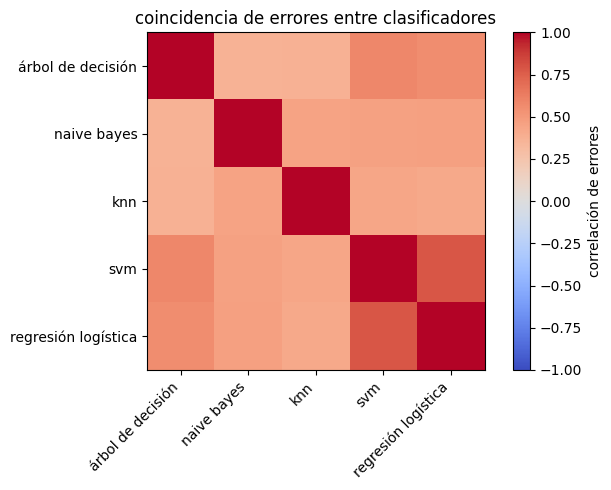

In [99]:
predicciones_base = recuperar_resultado("predicciones_oof_base")
if predicciones_base is None:
    predicciones_base = {}
    for nombre, modelo in modelos_base.items():
        print("predicción fuera de pliegue:", nombre, flush=True)
        predicciones_base[nombre] = cross_val_predict(
            modelo, x_desercion, y_desercion, cv=cv_desercion,
            n_jobs=n_trabajos, method="predict")
        guardar_resultado("predicciones_oof_base", predicciones_base)

errores = pd.DataFrame({nombre: (np.asarray(pred) != y_desercion.to_numpy()).astype(int)
    for nombre, pred in predicciones_base.items()})
correlacion_errores = errores.corr()
display(correlacion_errores.round(3))
fig, ax = plt.subplots(figsize=(7, 5))
im = ax.imshow(correlacion_errores.to_numpy(), vmin=-1, vmax=1, cmap="coolwarm")
ax.set_xticks(range(5), list(errores.columns), rotation=45, ha="right")
ax.set_yticks(range(5), list(errores.columns))
fig.colorbar(im, ax=ax, label="correlación de errores")
ax.set_title("coincidencia de errores entre clasificadores")
fig.tight_layout(); display(fig); plt.close(fig)

###Revisión
 La mayor correlación de errores se observó entre SVM y regresión logística (0.789). Esto significa que tienden a equivocarse con los mismos estudiantes, algo razonable porque ambos alcanzaron resultados similares. El árbol también comparte bastantes errores con SVM (0.564) y con logística (0.559). En cambio, kNN tiene correlaciones más moderadas con esos modelos (0.436 y 0.418), por lo que aporta algo más de diversidad.

Naive Bayes presentó correlaciones bajas o negativas, por ejemplo −0.318 con kNN. Eso puede parecer útil para un ensamble, pero hay que recordar su F1 macro de 0.2242: cometer errores diferentes no ayuda demasiado si el modelo se equivoca con mucha frecuencia. En los resultados, stacking (0.6883) superó ligeramente a la mejor base, logística (0.6870), mientras que la votación dura (0.6790) y la suave (0.6779) quedaron por debajo. Sí existe cierta diversidad, pero la coincidencia de errores entre los modelos fuertes limita lo que puede ganar una combinación simple.

## 11. Bagging optimizado: Random Forest y Extra-Trees

Aquí sí se pueden hacer búsquedas nuevas. Para cada biblioteca se evalúan 50 configuraciones diferentes mediante RandomizedSearchCV y cinco pliegues. Se varían max_features, criterio, profundidad/hojas y class_weight; Extra-Trees también prueba bootstrap.

In [100]:
def buscar_bagging(nombre):
    if nombre == "random forest":
        bosque = RandomForestClassifier(n_estimators=200, n_jobs=1, random_state=semilla)
    else:
        bosque = ExtraTreesClassifier(n_estimators=200, n_jobs=1, random_state=semilla)
    estimador = Pipeline([
        ("preprocesamiento", preprocesamiento_desercion(x_desercion, "arbol", incluir_mejora=True)),
        ("modelo", bosque)])
    espacio = {
        "modelo__max_features": ["sqrt", "log2", 0.4, 0.7, 1.0],
        "modelo__min_samples_leaf": [1, 2, 4, 6, 10],
        "modelo__max_depth": [None, 5, 8, 12, 18, 25],
        "modelo__criterion": ["gini", "entropy", "log_loss"],
        "modelo__class_weight": [None, "balanced", "balanced_subsample"]}
    if nombre == "extra trees":
        espacio["modelo__bootstrap"] = [True, False]
    return RandomizedSearchCV(
        estimador, espacio, n_iter=n_busquedas_ensamble, cv=cv_desercion,
        scoring="f1_macro", n_jobs=n_trabajos, random_state=semilla_busqueda,
        verbose=1, refit=True, error_score="raise", return_train_score=False)

busquedas_ensamble = {}
for nombre in ["random forest", "extra trees"]:
    clave = "busqueda_" + nombre.replace(" ", "_")
    objeto = recuperar_resultado(clave)
    if objeto is None:
        objeto = buscar_bagging(nombre)
        inicio = time.perf_counter()
        objeto.fit(x_desercion, y_desercion)
        objeto.tiempo_busqueda_p4_ = time.perf_counter() - inicio
        guardar_resultado(clave, objeto)
    busquedas_ensamble[nombre] = objeto
    print(nombre, "f1 búsqueda:", round(objeto.best_score_, 4))
    print("mejores parámetros:", objeto.best_params_)
    evaluar_desercion(nombre, objeto.best_estimator_, "bagging optimizado", getattr(objeto, "tiempo_busqueda_p4_", np.nan))

random forest f1 búsqueda: 0.6861
mejores parámetros: {'modelo__min_samples_leaf': 10, 'modelo__max_features': 'sqrt', 'modelo__max_depth': None, 'modelo__criterion': 'log_loss', 'modelo__class_weight': 'balanced'}
recuperado: random forest
extra trees f1 búsqueda: 0.6869
mejores parámetros: {'modelo__min_samples_leaf': 10, 'modelo__max_features': 0.4, 'modelo__max_depth': 18, 'modelo__criterion': 'log_loss', 'modelo__class_weight': 'balanced_subsample', 'modelo__bootstrap': False}
recuperado: extra trees


###Revisión
Se completaron las 50 configuraciones de cada búsqueda. Random Forest consiguió un F1 macro de 0.6861 ± 0.0132, con sensibilidad de 0.5512 para enrolled, mientras que Extra-Trees obtuvo 0.6869 ± 0.0157 y sensibilidad de 0.5764. La diferencia de F1 entre ambos fue de apenas 0.0008, por lo que no sería razonable afirmar que uno es claramente superior con estos resultados.

En los mejores parámetros, ambos eligieron el criterio log_loss y hojas con al menos 10 ejemplos. Random Forest quedó sin límite de profundidad, con max_features='sqrt' y pesos balanced. Extra-Trees eligió profundidad 18, max_features=0.4, pesos balanced_subsample y bootstrap=False. Las búsquedas tardaron aproximadamente 647 s y 513 s, respectivamente. Esto sugiere que aumentar la diversidad de árboles mediante cortes aleatorios puede funcionar tan bien como Random Forest, aunque ninguno superó a la mejor regresión logística base (0.6870).

## 12. Boosting optimizado: LightGBM y CatBoost

Comparación de dos bibliotecas distintas. Cada una prueba 50 configuraciones, se incluye tasa de aprendizaje, tamaño profundidad de árboles, regularización de las hojas, submuestreo de filas y columnas y los pesos por clase. Para CatBoost se emplea auto_class_weights, y para LightGBM class_weight ambos calculan los pesos dentro de cada ajuste no a partir de los pliegues externos

In [101]:
def buscar_boosting(nombre):
    pre = preprocesamiento_desercion(x_desercion, "arbol", incluir_mejora=True)
    if nombre == "lightgbm":
        estimador = LGBMClassifier(
            objective="multiclass", n_estimators=250, random_state=semilla,
            n_jobs=1, verbosity=-1, subsample_freq=1)
        espacio = {
            "modelo__learning_rate": loguniform(0.01, 0.2),
            "modelo__num_leaves": [7, 15, 31, 63],
            "modelo__max_depth": [-1, 3, 5, 8],
            "modelo__min_child_samples": [5, 10, 20, 40],
            "modelo__reg_lambda": loguniform(0.01, 10),
            "modelo__subsample": [0.65, 0.8, 1.0],
            "modelo__colsample_bytree": [0.65, 0.8, 1.0],
            "modelo__class_weight": [None, "balanced"]}
    else:
        estimador = CatBoostClassifier(
            loss_function="MultiClass", iterations=250,
            random_seed=semilla, thread_count=1, verbose=False,
            allow_writing_files=False, bootstrap_type="Bernoulli")
        espacio = {
            "modelo__learning_rate": loguniform(0.015, 0.18),
            "modelo__depth": [3, 4, 5, 6, 7],
            "modelo__l2_leaf_reg": loguniform(1, 15),
            "modelo__subsample": [0.65, 0.8, 1.0],
            "modelo__rsm": [0.65, 0.8, 1.0],
            "modelo__auto_class_weights": ["None", "Balanced", "SqrtBalanced"]}

    pipeline = Pipeline([("preprocesamiento", pre), ("modelo", estimador)])
    return RandomizedSearchCV(
        pipeline, espacio, n_iter=n_busquedas_ensamble,
        cv=cv_desercion, scoring="f1_macro", n_jobs=n_trabajos,
        random_state=semilla_busqueda, verbose=1,
        refit=True, error_score="raise")

for nombre in ["lightgbm", "catboost"]:
    clave = "busqueda_" + nombre
    objeto = recuperar_resultado(clave)
    if objeto is None:
        objeto = buscar_boosting(nombre)
        inicio = time.perf_counter()
        objeto.fit(x_desercion, y_desercion)
        objeto.tiempo_busqueda_p4_ = time.perf_counter() - inicio
        guardar_resultado(clave, objeto)
    busquedas_ensamble[nombre] = objeto
    print(nombre, "f1 búsqueda:", round(objeto.best_score_, 4))
    print("mejores parámetros:", objeto.best_params_)
    evaluar_desercion(nombre, objeto.best_estimator_, "boosting optimizado", getattr(objeto, "tiempo_busqueda_p4_", np.nan))

lightgbm f1 búsqueda: 0.696
mejores parámetros: {'modelo__class_weight': 'balanced', 'modelo__colsample_bytree': 0.65, 'modelo__learning_rate': np.float64(0.015706812000605114), 'modelo__max_depth': 5, 'modelo__min_child_samples': 10, 'modelo__num_leaves': 63, 'modelo__reg_lambda': np.float64(0.013253342600066534), 'modelo__subsample': 1.0}
recuperado: lightgbm
catboost f1 búsqueda: 0.6975
mejores parámetros: {'modelo__auto_class_weights': 'Balanced', 'modelo__depth': 5, 'modelo__l2_leaf_reg': np.float64(9.12427549454236), 'modelo__learning_rate': np.float64(0.1090561962175877), 'modelo__rsm': 0.65, 'modelo__subsample': 1.0}
recuperado: catboost


**Interpretación.** LightGBM y CatBoost utilizan boosting de árboles pero difieren en su construcción y tratamiento de divisiones. Ambos pueden capturar relaciones no lineales e interacciones entre variables que los clasificadores lineales no modelan directamente. El ganador se decidirá con las medias y desviaciones de F1 macro, no con la puntuación de entrenamiento.

## 13. Mesetas de las cuatro búsquedas optimizadas

Se muestra el mejor F1 macro acumulado contra el número de configuraciones evaluadas, y una tabla con los hiperparámetros ganadores. Las configuraciones fallidas no deben ocultarse: el gráfico ignora valores no finitos, y se informa cuántas fueron válidas.

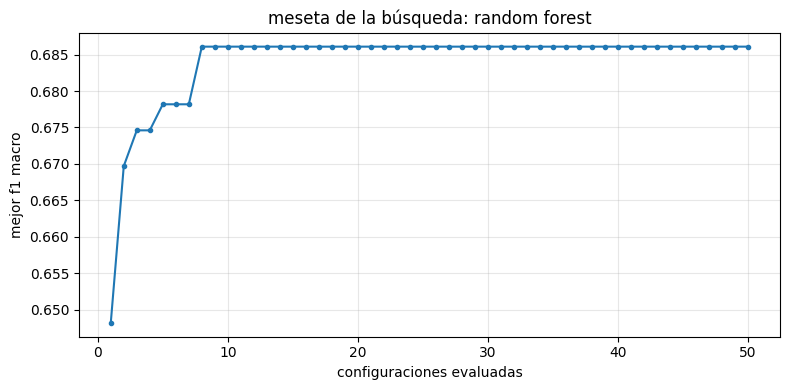

random forest configuraciones válidas: 50 / 50


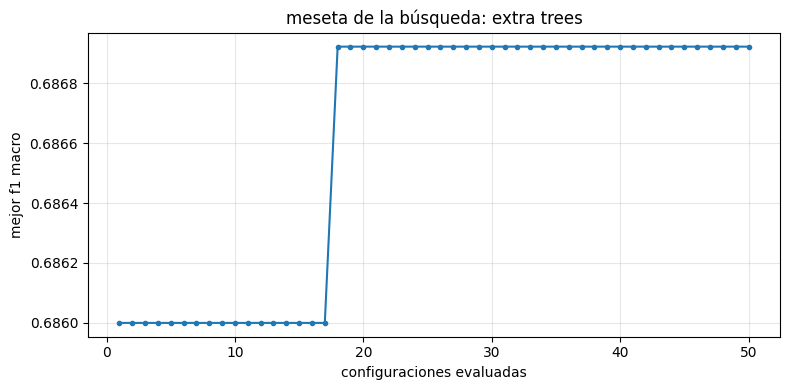

extra trees configuraciones válidas: 50 / 50


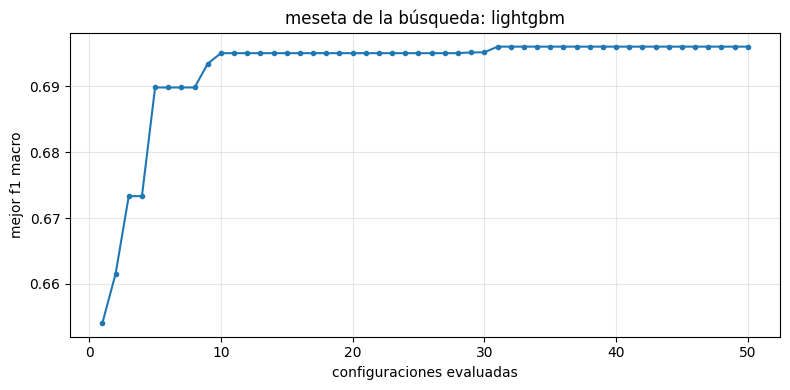

lightgbm configuraciones válidas: 50 / 50


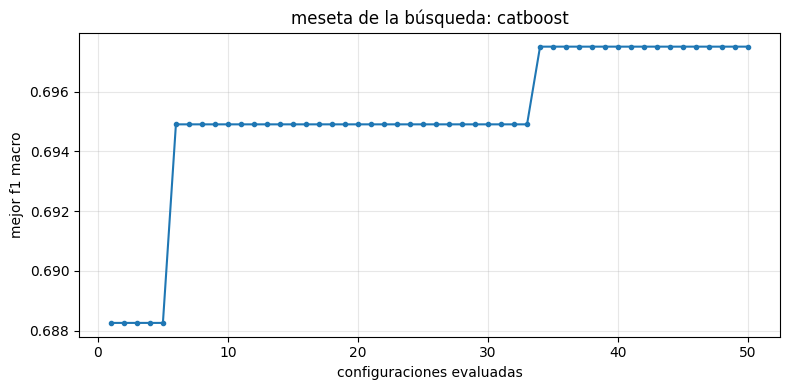

catboost configuraciones válidas: 50 / 50


,modelo,f1_busqueda,parametros
0,random forest,0.686088,"{'modelo__min_samples_leaf': 10, 'modelo__max_..."
1,extra trees,0.686922,"{'modelo__min_samples_leaf': 10, 'modelo__max_..."
2,lightgbm,0.696031,"{'modelo__class_weight': 'balanced', 'modelo__..."
3,catboost,0.697511,"{'modelo__auto_class_weights': 'Balanced', 'mo..."


In [102]:
configuraciones_ganadoras = []
for nombre, objeto in busquedas_ensamble.items():
    valores = np.asarray(objeto.cv_results_["mean_test_score"], dtype=float)
    finitos = np.isfinite(valores)
    mejor = np.maximum.accumulate(np.where(finitos, valores, -np.inf))
    mejor[~np.isfinite(mejor)] = np.nan
    fig, ax = plt.subplots(figsize=(8, 4))
    ax.plot(np.arange(1, len(valores) + 1), mejor, marker="o", markersize=3)
    ax.set(title=f"meseta de la búsqueda: {nombre}", xlabel="configuraciones evaluadas", ylabel="mejor f1 macro")
    ax.grid(alpha=0.3); fig.tight_layout(); display(fig); plt.close(fig)
    print(nombre, "configuraciones válidas:", finitos.sum(), "/", len(valores))
    configuraciones_ganadoras.append({"modelo": nombre, "f1_busqueda": objeto.best_score_,
                                    "parametros": str(objeto.best_params_)})
display(pd.DataFrame(configuraciones_ganadoras))

###Revisión
 Las cuatro búsquedas terminaron con 50 configuraciones válidas de 50. El mejor F1 macro encontrado fue 0.6861 para Random Forest, 0.6869 para Extra-Trees, 0.6960 para LightGBM y 0.6975 para CatBoost. Las gráficas permiten ver cuándo dejó de mejorar cada búsqueda: Random Forest se estabilizó aproximadamente desde la configuración 8, Extra-Trees desde la 18, LightGBM tuvo una pequeña mejora alrededor de la 31 y CatBoost encontró su mejor valor cerca de la 34.

Lo interesante es que en las dos bibliotecas de boosting todavía aparecieron mejoras después de varias configuraciones sin cambios. Por eso una meseta no demuestra que se encontró el mejor modelo posible, solo indica que las configuraciones probadas después de ese punto no mejoraron el resultado. Con el presupuesto de 50 intentos, boosting quedó por encima de los ensambles basados en bagging, aunque la ventaja de CatBoost frente a LightGBM (0.0015) es muy pequeña.

## 14. Tabla final de deserción y la matriz del mejor clasificador

La tabla reúne las cinco bases, las dos curvas de referencia (árbol completo y sus ensambles de 400), los métodos de votación, stacking y las cuatro búsquedas optimizadas. Se ordena por F1 macro e incluye desviación entre pliegues, sensibilidad enrolled y tiempo. Solo se presenta la matriz de confusión del mejor modelo.

guardado: resultados_p4/tabla_desercion.joblib


,modelo,familia,f1 ± desviación,sens_enrolled,tiempo_cv_s,tiempo_busqueda_s
6,catboost,boosting optimizado,0.6975 ± 0.0092,0.611,10.630,440.227
5,lightgbm,boosting optimizado,0.6960 ± 0.0152,0.602,6.294,178.149
15,stacking logístico,votación / stacking,0.6901 ± 0.0061,0.620,148.162,0.000
2,regresión logística,base fijo de práctica 3,0.6870 ± 0.0110,0.589,30.366,0.000
4,extra trees,bagging optimizado,0.6869 ± 0.0157,0.576,24.443,512.663
3,random forest,bagging optimizado,0.6861 ± 0.0132,0.551,9.942,647.458
1,svm,base fijo de práctica 3,0.6853 ± 0.0062,0.617,17.062,0.000
13,votación dura,votación / stacking,0.6790 ± 0.0055,0.627,28.731,0.000
14,votación suave,votación / stacking,0.6779 ± 0.0081,0.665,48.385,0.000
8,bagging 400,varianza,0.6620 ± 0.0227,0.331,91.710,0.000


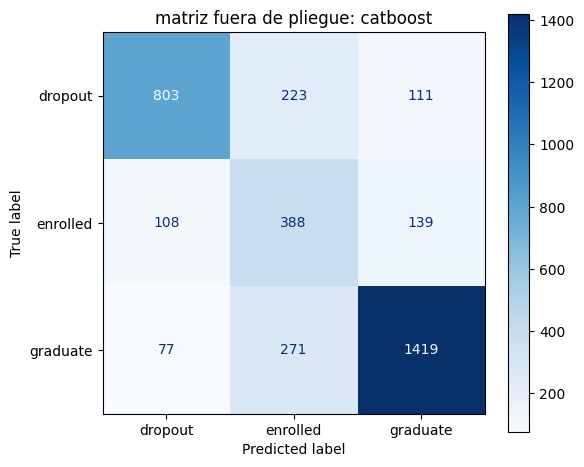

mejor en deserción: catboost


In [103]:
#añadir los extremos de las dos curvas como modelos ya evaluados en los mismos cinco pliegues
for nombre, tabla, n, familia in [
    ("árbol completo", resumen_bagging, 0, "varianza"),
    ("bagging 400", resumen_bagging, 400, "varianza"),
    ("tocón", resumen_boosting, 0, "sesgo"),
    ("adaboost 400", resumen_boosting, 400, "sesgo")]:
    if nombre not in resultados_desercion:
        resultados_desercion[nombre] = {
            "modelo": nombre, "familia": familia,
            "f1_media": float(tabla.loc[n, "mean"]), "f1_std": float(tabla.loc[n, "std"]),
            "sens_enrolled": float((curva_bagging if "bagging" in nombre or "árbol" in nombre else curva_boosting).query("n == @n")["sens"].mean()),
            "tiempo_cv_s": float((curva_bagging if "bagging" in nombre or "árbol" in nombre else curva_boosting).query("n == @n")["tiempo_s"].sum()),
            "tiempo_busqueda_s": 0.0, "tiempo_pared_s": np.nan}

modelos_desercion["árbol completo"] = Pipeline([
    ("preprocesamiento", preprocesamiento_desercion(x_desercion, "arbol", incluir_mejora=False)),
    ("modelo", DecisionTreeClassifier(random_state=semilla))])
modelos_desercion["tocón"] = Pipeline([
    ("preprocesamiento", preprocesamiento_desercion(x_desercion, "arbol", incluir_mejora=False)),
    ("modelo", DecisionTreeClassifier(max_depth=1, random_state=semilla))])
modelos_desercion["bagging 400"] = Pipeline([
    ("preprocesamiento", preprocesamiento_desercion(x_desercion, "arbol", incluir_mejora=False)),
    ("modelo", BaggingClassifier(estimator=DecisionTreeClassifier(), n_estimators=400,
                                   random_state=semilla, n_jobs=n_trabajos))])
modelos_desercion["adaboost 400"] = Pipeline([
    ("preprocesamiento", preprocesamiento_desercion(x_desercion, "arbol", incluir_mejora=False)),
    ("modelo", AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=1),
                                    n_estimators=400, learning_rate=0.5, random_state=semilla))])

#las curvas ya calcularon f1, sensibilidad y tiempos de cada pliegue
#no se vuelven a entrenar 400 árboles para construir la tabla.
guardar_resultado("tabla_desercion", resultados_desercion)

tabla_desercion = pd.DataFrame(resultados_desercion.values()).sort_values("f1_media", ascending=False)
tabla_desercion["f1 ± desviación"] = tabla_desercion.apply(
    lambda r: f"{r['f1_media']:.4f} ± {r['f1_std']:.4f}", axis=1)
display(tabla_desercion[["modelo", "familia", "f1 ± desviación", "sens_enrolled", "tiempo_cv_s", "tiempo_busqueda_s"]].round(3))

ganador_desercion = tabla_desercion.iloc[0]["modelo"]
pred_oof_ganador = recuperar_resultado("predicciones_oof_ganador_desercion")
if pred_oof_ganador is None or pred_oof_ganador.get("modelo") != ganador_desercion:
    pred = cross_val_predict(modelos_desercion[ganador_desercion], x_desercion, y_desercion,
                             cv=cv_desercion, n_jobs=n_trabajos)
    pred_oof_ganador = {"modelo": ganador_desercion, "pred": pred}
    guardar_resultado("predicciones_oof_ganador_desercion", pred_oof_ganador)

matriz = confusion_matrix(y_desercion, pred_oof_ganador["pred"], labels=clases_desercion)
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(matriz, display_labels=clases_desercion).plot(ax=ax, cmap="Blues", values_format="d")
ax.set_title("matriz fuera de pliegue: " + ganador_desercion)
fig.tight_layout(); display(fig); plt.close(fig)
print("mejor en deserción:", ganador_desercion)

###Revisión
 El mejor modelo de deserción fue CatBoost, con un F1 macro de 0.6975 ± 0.0092, frente a 0.6870 ± 0.0110 de la mejor base, regresión logística. La ganancia fue de 0.0105 puntos (1.05 puntos porcentuales). LightGBM quedó muy cerca, con 0.6960 ± 0.0152, así que no podemos interpretar esa diferencia tan pequeña como una superioridad garantizada de CatBoost fuera de estos pliegues.

En la matriz de CatBoost se clasificaron correctamente 803 de 1,137 estudiantes dropout, 388 de 635 enrolled y 1,419 de 1,767 graduate. La sensibilidad de enrolled fue de aproximadamente 0.6110: todavía hubieron 108 estudiantes de esta clase clasificados como dropout y 139 como graduate. Esta sigue siendo la clase más difícil de reconocer. Además, la votación suave alcanzó una sensibilidad mayor para enrolled (0.6646), pero con peor F1 macro (0.6779), lo que muestra que mejorar una clase no garantiza mejorar el equilibrio general.

El resultado respalda que boosting fue la familia más competitiva en este conjunto, sin embargo, los hiperparámetros de los modelos optimizados se eligieron utilizando los mismos datos de los cinco pliegues, así que la puntuación podría ser algo optimista.

# Parte 2 · Bank Marketing
## 15. Descargar el archivo completo y quitar *duration*

Se utiliza bank-additional-full.csv de UCI (41,188 registros, separador ;). Se borra duration porque esa duración solo se conoce después de la llamada y no se debe utilizar para una predicción previa. La variable objetivo es y: yes = 1, no = 0. Se usan las mismas cinco particiones para todos los modelos con semilla 2026.

In [104]:
#descargar el dataset de bank marketing
from pathlib import Path
from urllib.request import urlretrieve
from io import BytesIO
import zipfile
import pandas as pd

ruta_banco = carpeta_datos / "bank-additional-full.csv"
zip_banco = carpeta_datos / "bank+marketing.zip"

url_banco = "https://archive.ics.uci.edu/static/public/222/bank+marketing.zip"

if not ruta_banco.exists():

    #comprobar que no haya una descarga dañada
    if zip_banco.exists() and not zipfile.is_zipfile(zip_banco):
        zip_banco.unlink()

    #descargar solo si hace falta
    if not zip_banco.exists():
        print("descargando bank marketing...")
        urlretrieve(url_banco, zip_banco)

    #abrir el zip principal
    with zipfile.ZipFile(zip_banco) as paquete:

        nombres = paquete.namelist()

        csv_directo = next(
            (n for n in nombres if n.endswith("bank-additional-full.csv")),
            None)

        if csv_directo:
            contenido = paquete.read(csv_directo)

        else:
            # encontrar el zip interno
            archivo_interno = next(
                (n for n in nombres if n.endswith("bank-additional.zip")),
                None)

            if archivo_interno is None:
                raise FileNotFoundError("no se encontró bank-additional.zip")

            with zipfile.ZipFile(
                BytesIO(paquete.read(archivo_interno))) as interno:

                archivo_csv = next(
                    (n for n in interno.namelist()
                        if n.endswith("bank-additional-full.csv")),
                    None)

                if archivo_csv is None:
                    raise FileNotFoundError("no se encontró el csv completo")

                contenido = interno.read(archivo_csv)

    ruta_banco.write_bytes(contenido)

#cargar los datos
banco = pd.read_csv(ruta_banco, sep=";")

#comprobar el dataset
assert banco.shape[0] == 41188
assert {"duration", "y"}.issubset(banco.columns)

#separar las características y variable objetivo
x_banco = banco.drop(columns=["duration", "y"]).copy()
y_banco = banco["y"].map({"no": 0, "yes": 1}).astype(int)

print("bank marketing:", x_banco.shape)
print("proporción de yes:", round(y_banco.mean() * 100, 2), "%")

display(banco.head())

bank marketing: (41188, 19)
proporción de yes: 11.27 %


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


###Revisión
Se descargó correctamente el archivo completo de Bank Marketing: 41,188 registros y 19 variables de entrada después de quitar duration y la variable objetivo y. La proporción de yes fue de 11.27 % (4,640 clientes), frente a 88.73 % de no (36,548 clientes). Es decir, hay muchos más ejemplos de personas que no contrataron el depósito.

Este desbalance hace que una exactitud alta pueda ser engañosa: un modelo podría acertar casi siempre diciendo no y aun así detectar pocos clientes interesados. Por eso usamos F1 macro y se revisan por separado la sensibilidad de yes. También es correcto excluir duration, porque representa información de la llamada que no estaría disponible antes de realizarla y podría producir una evaluación poco realista.

## 16. Preprocesamiento del banco dentro de pipelines

Las columnas categóricas (job, marital, education, etc.) se imputan y codifican; las numéricas se imputan por mediana y se escalan solo cuando el modelo lo necesita. Esta transformación se ajusta únicamente dentro de los pliegues de entrenamiento. Se evita calcular umbrales a partir de todo el conjunto.

In [105]:
columnas_cat_banco = x_banco.select_dtypes(include=["object", "category"]).columns.tolist()
columnas_num_banco = [c for c in x_banco.columns if c not in columnas_cat_banco]


def preprocesamiento_banco(modo="arbol"):
    categorias = Pipeline([
        ("relleno", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))])
    numeros = [("relleno", SimpleImputer(strategy="median"))]
    if modo == "escalado":
        numeros.append(("escala", StandardScaler()))
    if modo == "bayes":
        numeros.append(("escala", MinMaxScaler()))
    return ColumnTransformer([
        ("categoricas", categorias, columnas_cat_banco),
        ("numericas", Pipeline(numeros), columnas_num_banco)], remainder="drop")

print("categóricas:", columnas_cat_banco)
print("numéricas:", columnas_num_banco)

categóricas: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome']
numéricas: ['age', 'campaign', 'pdays', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']


###Revisión
El conjunto del banco quedó dividido en 10 variables categóricas (job, marital, education, default, housing, loan, contact, month, day_of_week y poutcome) y 9 numéricas, entre ellas age, campaign, pdays y euribor3m. Para los modelos que lo necesitan, las categorías se convierten en indicadores mediante one-hot, por lo que el número de columnas transformadas puede superar las 19 variables originales.

Es importante que la imputación, la codificación y el escalado estén dentro de cada Pipeline, así se calculan solamente con los datos de entrenamiento de cada pliegue. CatBoost usa un camino distinto, pues recibe las columnas categóricas directamente. Esto permite comparar dos maneras de trabajar con los mismos datos sin usar información del pliegue de prueba para preparar las variables.

## 17. Modelos candidatos y optimización interna del banco

Se comparan regresión logística, un árbol, Naive Bayes, Random Forest, Extra-Trees, LightGBM y CatBoost, además de trasladar a este conjunto la familia ganadora en deserción (con preprocesamiento bancario, no con parámetros de entrada incompatibles). Los dos últimos se optimizan dentro de cada pliegue externo mediante RandomizedSearchCV con 3 pliegues internos. Este diseño exige más ajustes, pero es preferible a escoger parámetros utilizando la misma validación con la que se reporta el F1. También se incluye un modelo con umbral de decisión optimizado internamente para maximizar F1 macro.

Para que el tiempo sea manejable en CPU, el banco usa 24 configuraciones internas de LightGBM y 16 de CatBoost por pliegue externo.

La versión de CatBoost para el banco trabaja directamente con las columnas categóricas originales mediante cat_features, lo que permite aprovechar su tratamiento nativo de categorías. La codificación queda dentro del propio estimador entrenado en cada pliegue. El CSV oficial usa unknown en lugar de categorías faltantes.


In [106]:
def buscar_lgbm_banco():
    pipeline = Pipeline([
        ("preprocesamiento", preprocesamiento_banco("arbol")),
        ("modelo", LGBMClassifier(n_estimators=250, objective="binary", n_jobs=1,
                                   random_state=2026, verbosity=-1, subsample_freq=1))])
    espacio = {
        "modelo__learning_rate": loguniform(0.015, 0.18),
        "modelo__num_leaves": [15, 31, 63],
        "modelo__min_child_samples": [10, 20, 40, 80],
        "modelo__reg_lambda": loguniform(0.01, 15),
        "modelo__subsample": [0.7, 0.85, 1.0],
        "modelo__colsample_bytree": [0.7, 0.85, 1.0],
        "modelo__class_weight": [None, "balanced"]}
    return RandomizedSearchCV(pipeline, espacio, n_iter=n_busquedas_banco_lgbm,
                              scoring="f1_macro", cv=StratifiedKFold(3, shuffle=True, random_state=2026),
                              n_jobs=n_trabajos, random_state=2026, refit=True,
                              verbose=0, error_score="raise")


def buscar_cat_banco():
    pipeline = Pipeline([
        ("preprocesamiento", "passthrough"),
        ("modelo", CatBoostClassifier(
        cat_features=tuple(columnas_cat_banco), iterations=200)),])
    espacio = {
        "modelo__learning_rate": loguniform(0.02, 0.2),
        "modelo__depth": [4, 5, 6, 7],
        "modelo__l2_leaf_reg": loguniform(1, 15),
        "modelo__subsample": [0.7, 0.85, 1.0],
        "modelo__rsm": [0.7, 0.85, 1.0],
        "modelo__auto_class_weights": [None, "Balanced", "SqrtBalanced"]}
    return RandomizedSearchCV(pipeline, espacio, n_iter=n_busquedas_banco_cat,
                              scoring="f1_macro", cv=StratifiedKFold(3, shuffle=True, random_state=2026),
                              n_jobs=n_trabajos, random_state=2026, refit=True,
                              verbose=0, error_score="raise")

modelos_banco = {
    "regresión logística": Pipeline([
        ("preprocesamiento", preprocesamiento_banco("escalado")),
        ("modelo", LogisticRegression(solver="lbfgs", max_iter=1500, class_weight="balanced"))]),
    "árbol": Pipeline([
        ("preprocesamiento", preprocesamiento_banco("arbol")),
        ("modelo", DecisionTreeClassifier(max_depth=8, min_samples_leaf=30,
                                            class_weight="balanced", random_state=2026))]),
    "naive bayes": Pipeline([
        ("preprocesamiento", preprocesamiento_banco("bayes")),
        ("modelo", GaussianNB(var_smoothing=1e-8))]),
    "random forest": Pipeline([
        ("preprocesamiento", preprocesamiento_banco("arbol")),
        ("modelo", RandomForestClassifier(n_estimators=200, min_samples_leaf=5,
                                           class_weight="balanced", n_jobs=1, random_state=2026))]),
    "extra trees": Pipeline([
        ("preprocesamiento", preprocesamiento_banco("arbol")),
        ("modelo", ExtraTreesClassifier(n_estimators=200, min_samples_leaf=5,
                                         class_weight="balanced", n_jobs=1, random_state=2026))]),
    "lightgbm optimizado": buscar_lgbm_banco(),
    "catboost optimizado": buscar_cat_banco(),
    "lightgbm con umbral": TunedThresholdClassifierCV(
        estimator=Pipeline([
            ("preprocesamiento", preprocesamiento_banco("arbol")),
            ("modelo", LGBMClassifier(n_estimators=300, num_leaves=31, learning_rate=0.05,
                                       min_child_samples=30, colsample_bytree=0.8,
                                       n_jobs=1, random_state=2026, verbosity=-1))]),
        scoring="f1_macro", cv=3, thresholds=np.linspace(0.08, 0.72, 65),
        n_jobs=1, refit=True, random_state=2026)}

def transferir_ganador_desercion():
    ganador = tabla_desercion.iloc[0]["modelo"]
    original = modelos_desercion[ganador]

    if isinstance(original, Pipeline) and "modelo" in original.named_steps:
        estimador = clone(original.named_steps["modelo"])
        params = estimador.get_params()
        if isinstance(estimador, LGBMClassifier):
            estimador.set_params(objective="binary")
        if isinstance(estimador, CatBoostClassifier):
            estimador.set_params(loss_function="Logloss")
        modo = "escalado" if isinstance(estimador, (SVC, LogisticRegression, KNeighborsClassifier)) else (
            "bayes" if isinstance(estimador, (GaussianNB, MultinomialNB, BernoulliNB)) else "arbol")
        return Pipeline([("preprocesamiento", preprocesamiento_banco(modo)), ("modelo", estimador)])

    #si ganó la votación o el stacking, se reproduce la misma familia sobre variables bancarias
    bases = [
        ("arbol", clone(modelos_banco["árbol"])),
        ("bayes", clone(modelos_banco["naive bayes"])),
        ("knn", Pipeline([("preprocesamiento", preprocesamiento_banco("escalado")),
                          ("modelo", KNeighborsClassifier(n_neighbors=7, algorithm="kd_tree"))])),
        ("svm", Pipeline([("preprocesamiento", preprocesamiento_banco("escalado")),
                          ("modelo", SVC(kernel="linear", C=0.3, class_weight="balanced"))])),
        ("logistica", clone(modelos_banco["regresión logística"])),]
    if ganador == "votación dura":
        return VotingClassifier(estimators=bases, voting="hard")
    probabilidades = [(nombre, modelo) for nombre, modelo in bases if nombre != "svm"]
    calibrado = CalibratedClassifierCV(estimator=bases[3][1], cv=3, method="sigmoid", ensemble=False)
    probabilidades.insert(3, ("svm", calibrado))
    if ganador == "votación suave":
        return VotingClassifier(estimators=probabilidades, voting="soft")
    return StackingClassifier(estimators=probabilidades,
                              final_estimator=LogisticRegression(class_weight="balanced", max_iter=1000),
                              cv=3, stack_method="predict_proba")

modelos_banco["familia ganadora de deserción"] = transferir_ganador_desercion()
print("ganador original:", tabla_desercion.iloc[0]["modelo"])
print("candidatos:", list(modelos_banco))

ganador original: catboost
candidatos: ['regresión logística', 'árbol', 'naive bayes', 'random forest', 'extra trees', 'lightgbm optimizado', 'catboost optimizado', 'lightgbm con umbral', 'familia ganadora de deserción']


### Revisión
 LightGBM y CatBoost exploran estructuras no lineales y desbalance dentro de cada entrenamiento. El ajuste interno del umbral cambia el punto a partir del cual se predice yes; con clases desbalanceadas, el umbral 0.5 no siempre maximiza F1 macro. No se permite escogerlo mirando las predicciones del pliegue externo.

In [107]:
#corrección de los pesos de catboost sin repetir los modelos anteriores
busqueda_cat = modelos_banco["catboost optimizado"]

#mantener el espacio de búsqueda y cambiar solo los pesos
espacio_corregido = dict(busqueda_cat.param_distributions)

espacio_corregido["modelo__auto_class_weights"] = [
    "Balanced",
    "SqrtBalanced"]

busqueda_cat.set_params(
    param_distributions=espacio_corregido)

#establecer un valor válido también en el modelo base
busqueda_cat.estimator.set_params(
    modelo__auto_class_weights="Balanced")

print("catboost corregido")
print(
    "pesos disponibles:",
    busqueda_cat.param_distributions["modelo__auto_class_weights"])

catboost corregido
pesos disponibles: ['Balanced', 'SqrtBalanced']


## 18. Evaluación con `cross_validate` y resumen del banco

Como requisito de la práctica, cada F1 macro se calcula usando cross_validate(modelo, X, y, cv=cv_banco, scoring='f1_macro'), que es equivalente cuando se añaden otras métricas en scoring. Las búsquedas y el ajuste del umbral son parte del modelo que recibe cross_validate. La sensibilidad de yes es el recall de la clase 1.

In [108]:
resultados_banco = recuperar_resultado("tabla_banco")
if resultados_banco is None:
    resultados_banco = {}

for nombre, modelo in modelos_banco.items():
    if nombre in resultados_banco:
        print("recuperado:", nombre)
        continue
    print("evaluando bank marketing:", nombre, flush=True)
    inicio = time.perf_counter()
    salida = cross_validate(
        modelo, x_banco, y_banco, cv=cv_banco,
        scoring={"f1": "f1_macro", "sens": make_scorer(recall_score, pos_label=1)},
        n_jobs=1, error_score="raise", return_estimator=False)
    resultados_banco[nombre] = {
        "modelo": nombre,
        "f1_media": float(salida["test_f1"].mean()),
        "f1_std": float(salida["test_f1"].std(ddof=1)),
        "sens_yes": float(salida["test_sens"].mean()),
        "tiempo_cv_s": float(np.sum(salida["fit_time"])),
        "tiempo_pared_s": float(time.perf_counter() - inicio)}
    guardar_resultado("tabla_banco", resultados_banco)

tabla_banco = pd.DataFrame(resultados_banco.values()).sort_values("f1_media", ascending=False)
tabla_banco["f1 ± desviación"] = tabla_banco.apply(
    lambda r: f"{r['f1_media']:.4f} ± {r['f1_std']:.4f}", axis=1)
display(tabla_banco[["modelo", "f1 ± desviación", "sens_yes", "tiempo_cv_s"]].round(3))

recuperado: regresión logística
recuperado: árbol
recuperado: naive bayes
recuperado: random forest
recuperado: extra trees
recuperado: lightgbm optimizado
recuperado: catboost optimizado
recuperado: lightgbm con umbral
recuperado: familia ganadora de deserción


,modelo,f1 ± desviación,sens_yes,tiempo_cv_s
6,catboost optimizado,0.7174 ± 0.0069,0.534,2365.891
3,random forest,0.7115 ± 0.0054,0.592,38.082
5,lightgbm optimizado,0.6920 ± 0.0048,0.624,413.898
4,extra trees,0.6915 ± 0.0071,0.609,43.579
8,familia ganadora de deserción,0.6872 ± 0.0040,0.643,15.026
0,regresión logística,0.6739 ± 0.0045,0.629,7.181
1,árbol,0.6727 ± 0.0148,0.631,2.510
2,naive bayes,0.6477 ± 0.0082,0.602,1.057
7,lightgbm con umbral,0.5716 ± 0.0067,0.114,29.776


###Revisión
En Bank Marketing CatBoost optimizado consiguió el mejor F1 macro con 0.7174 ± 0.0069, seguido por Random Forest (0.7115 ± 0.0054). La ventaja fue de 0.0059 puntos, relativamente pequeña. Además, el costo fue muy distinto: CatBoost acumuló aproximadamente 2,366 s de entrenamiento en la validación, frente a 38 s de Random Forest. Si solo se necesitara un modelo rápido, este último sería una alternativa interesante.

La sensibilidad de yes también muestra un compromiso: CatBoost recuperó alrededor del 53.4 % de los clientes que sí contrataron, mientras que Random Forest llegó al 59.2 % y LightGBM al 62.4 %, aunque con menor F1 macro global. La versión LightGBM con umbral quedó en 0.5716 ± 0.0067, con sensibilidad de apenas 0.114; en esta ejecución ajustar el umbral no ayudó. Comparado con deserción, volvió a ganar la familia CatBoost, pero los parámetros se optimizaron para un problema distinto. No significa que los valores aprendidos o la configuración de deserción se puedan trasladar directamente al banco.

## 19. Matriz de confusión **únicamente del mejor modelo** y exportación

Se selecciona el primer modelo de la tabla del banco, se obtiene una predicción fuera de pliegue para cada fila y se presenta su única matriz de confusión. Finalmente se ajusta ese mismo procedimiento completo sobre los 41,188 registros.

El F1 reportado viene de cinco pliegues de evaluación. El modelo exportado se ajusta sobre todos los datos y no se usa para informar ese F1.

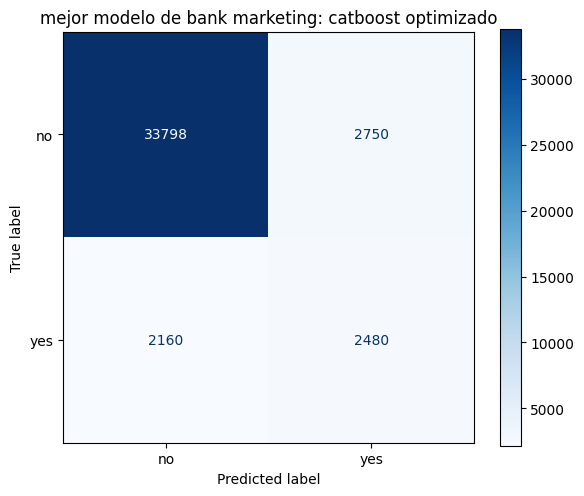

modelo guardado: MaríaVillanueva-catboost_optimizado.joblib ( 0.14 MB )
clases del modelo: [0 1]


In [109]:
ganador_banco = tabla_banco.iloc[0]["modelo"]
pred_oof_banco = recuperar_resultado("predicciones_oof_ganador_banco")
if pred_oof_banco is None or pred_oof_banco.get("modelo") != ganador_banco:
    print("calculando matriz final de banco:", ganador_banco, flush=True)
    pred = cross_val_predict(modelos_banco[ganador_banco], x_banco, y_banco,
                             cv=cv_banco, n_jobs=1)
    pred_oof_banco = {"modelo": ganador_banco, "pred": pred}
    guardar_resultado("predicciones_oof_ganador_banco", pred_oof_banco)

matriz_banco = confusion_matrix(y_banco, pred_oof_banco["pred"], labels=[0, 1])
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(matriz_banco, display_labels=["no", "yes"]).plot(
    ax=ax, cmap="Blues", values_format="d")
ax.set_title("mejor modelo de bank marketing: " + ganador_banco)
fig.tight_layout(); display(fig); plt.close(fig)

import unicodedata
nombre_normalizado = unicodedata.normalize("NFKD", ganador_banco).encode("ascii", "ignore").decode("ascii")
nombre_archivo = "MaríaVillanueva-" + nombre_normalizado.replace(" ", "_") + ".joblib"
ruta_modelo = Path(nombre_archivo)  # guardar con nombre solicitado en la raíz del proyecto
modelo_exportado = recuperar_resultado("modelo_final_banco_" + ganador_banco.replace(" ", "_"))
if modelo_exportado is None:
    modelo_exportado = clone(modelos_banco[ganador_banco])
    print("entrenando el ganador con todo bank marketing...", flush=True)
    modelo_exportado.fit(x_banco, y_banco)
    guardar_resultado("modelo_final_banco_" + ganador_banco.replace(" ", "_"), modelo_exportado)

joblib.dump(modelo_exportado, ruta_modelo, compress=3)
if carpeta_drive is not None:
    import shutil
    shutil.copy2(ruta_modelo, carpeta_drive / ruta_modelo.name)

print("modelo guardado:", ruta_modelo, "(", round(ruta_modelo.stat().st_size / 1e6, 2), "MB )")
print("clases del modelo:", modelo_exportado.classes_)

###Revisión
La matriz de confusión corresponde a CatBoost optimizado, que fue el ganador en Bank Marketing. De los clientes que realmente respondieron no, clasificó correctamente 33,798 y produjo 2,750 falsos positivos. Entre quienes sí contrataron (yes), detectó 2,480, pero dejó pasar 2,160 falsos negativos. Eso equivale aproximadamente a 53.4 % de sensibilidad para yes, 47.4 % de precisión en sus predicciones positivas y 92.5 % de especificidad para no.

Aunque el F1 macro de 0.7174 fue el más alto de la tabla, todavía se escapa casi la mitad de los clientes que sí contratarían. Esto es importante si el objetivo fuera identificar oportunidades comerciales: habría que considerar también el costo de contactar a alguien sin interés y el de no contactar a alguien que sí lo tiene.

## 20. Comparación entre problemas y conclusiones

Este bloque hace un resumen basado en los resultados calculados.

In [110]:
ganador_desercion = tabla_desercion.iloc[0]["modelo"]
ganador_banco = tabla_banco.iloc[0]["modelo"]
mejora_vs_base = float(tabla_desercion.iloc[0]["f1_media"] - max(
    resultados_desercion[n]["f1_media"] for n in nombres_base))

print("mejor deserción:", ganador_desercion)
print("mejor bank marketing:", ganador_banco)
print("ventaja del mejor de deserción frente al mejor base:", round(mejora_vs_base, 4))
print("mejor f1 banco:", round(float(tabla_banco.iloc[0]["f1_media"]), 4))

if ganador_desercion != ganador_banco:
    print("no ganó exactamente el mismo modelo en los dos problemas")
else:
    print("ganó el mismo nombre de modelo en los dos problemas")

mejor deserción: catboost
mejor bank marketing: catboost optimizado
ventaja del mejor de deserción frente al mejor base: 0.0105
mejor f1 banco: 0.7174
no ganó exactamente el mismo modelo en los dos problemas


### Interpretación y conclusiones

Bagging pretende estabilizar árboles que cambian mucho con la muestra, por lo que su beneficio principal suele observarse al comparar contra un árbol profundo. AdaBoost trabaja sobre reglas simples y construye progresivamente una decisión más expresiva. Votación y stacking solo pueden aprovechar diferencias entre modelos cuando existe suficiente diversidad de errores, la matriz de correlaciones ayuda a evaluar esa condición. Random Forest y Extra-Trees ofrecen variantes de bagging con selección aleatoria de variables o cortes, LightGBM y CatBoost representan boosting más flexible.

En Bank Marketing se trabaja con 41,188 filas y un objetivo binario fuertemente desbalanceado, mientras que deserción tiene 3,539 filas de entrenamiento y tres clases. Estas diferencias cambian la importancia relativa del sesgo, la varianza, el desbalance y el umbral de decisión. Por eso no debe suponerse que la misma familia ganará necesariamente en ambos conjuntos. La elección final se respalda en las tablas y matrices generadas, no en la complejidad del algoritmo.
La configuración exacta de los dos clasificadores base de la Práctica 3 que no pudieran recuperarse de Drive es aproximada; las búsquedas optimizadas de deserción se seleccionan utilizando los mismos datos luego evaluados por CV (posible optimismo), mientras que las búsquedas de Bank Marketing sí se ejecutan dentro de los pliegues externos. No se conoce el F1 futuro del modelo exportado hasta evaluarlo con nuevas observaciones. No se utilizó duration ni información del segundo semestre en la predicción temprana.

**Declaración sobre el uso de inteligencia artificial**

Para la realización de esta práctica se utilizó *ChatGPT* como herramienta de soporte técnico, pedagógico y de redacción.
Alcance de uso:
* Soporte de código y resolución de errores
* Supervisión de formato de texto.
* Supervisión y sugerencia formato README.md



In [111]:
# comprimir los resultados para conservar los entrenamientos

from pathlib import Path
import shutil

carpeta = Path("resultados_p4")

if not carpeta.exists():
    raise FileNotFoundError("no se encontró la carpeta resultados_p4")

archivo_zip = shutil.make_archive(
    "resultados_p4",
    "zip",
    root_dir=".",
    base_dir="resultados_p4"
)

print("archivo generado:", archivo_zip)
print("tamaño:", round(Path(archivo_zip).stat().st_size / 1024**2, 2), "MB")

archivo generado: /content/resultados_p4.zip
tamaño: 6.76 MB
